# Task 4 (Medium) – Trend Analysis by Release Year
**Auspify Technologies · Data Analysis Using Python Internship**

**Goal:** Analyze how Netflix content production has changed over time.

| Step | Description |
|---|---|
| 1 | Organize content by release year |
| 2 | Calculate yearly content releases |
| 3 | Identify growth and decline trends |
| 4 | Create trend visualizations |
| 5 | Interpret business patterns |

In [1]:
import sys
sys.path.insert(0, '../src')   # makes netflix_utils importable from the notebooks folder

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from netflix_utils import *

## Step 1 – Organize content by release year

In [3]:
df = load_clean()
print(f"Release years span {df.release_year.min()} – {df.release_year.max()}")
print(f"Titles released before 2000: {(df.release_year < 2000).sum():,} ({pct((df.release_year < 2000).sum(), len(df))}%)")
START = 2000                                   # focus window: the catalogue is thin before 2000
win = df[df.release_year >= START]
print(f"Analysis window {START}-2021: {len(win):,} titles ({pct(len(win), len(df))}% of catalogue)")

Release years span 1925 – 2021
Titles released before 2000: 525 (6.0%)
Analysis window 2000-2021: 8,261 titles (94.0% of catalogue)


## Step 2 – Yearly content releases

In [4]:
yearly_all = df.groupby("release_year").size().rename("titles")
yearly = (win.groupby(["release_year", "type"]).size().unstack(fill_value=0)
          .rename(columns={"Movie": "movies", "TV Show": "tv_shows"}))
yearly["titles"] = yearly.movies + yearly.tv_shows
yearly["yoy_pct"] = (yearly.titles.pct_change() * 100).round(1)
yearly["rolling_3yr_avg"] = yearly.titles.rolling(3, center=True).mean().round(1)
yearly["tv_share_pct"] = (yearly.tv_shows / yearly.titles * 100).round(1)
yearly.to_csv(REPORTS / "task4_yearly_releases.csv")
yearly_all.to_csv(REPORTS / "task4_all_years_releases.csv")
yearly.tail(12)

type,movies,tv_shows,titles,yoy_pct,rolling_3yr_avg,tv_share_pct
release_year,,,,,,
2010,153,39,192,26.3,176.3,20.3
2011,145,40,185,-3.6,204.3,21.6
2012,173,63,236,27.6,235.7,26.7
2013,225,61,286,21.2,291.0,21.3
2014,263,88,351,22.7,397.3,25.1
2015,396,159,555,58.1,602.3,28.6
2016,658,243,901,62.3,828.7,27.0
2017,765,265,1030,14.3,1025.0,25.7
2018,766,378,1144,11.1,1067.7,33.0


## Step 3 – Growth and decline trends

In [5]:
peak_year = int(yearly.titles.idxmax()); peak_val = int(yearly.titles.max())
last_full = 2020                                 # 2021 is partial
cagr = lambda a, b, n: ((b / a) ** (1 / n) - 1) * 100
cagr_2010_2018 = cagr(yearly.loc[2010, "titles"], yearly.loc[2018, "titles"], 8)
decline_2018_2020 = (yearly.loc[2020, "titles"] / yearly.loc[2018, "titles"] - 1) * 100
phase = []
for a, b, lbl in [(2000, 2009, "2000-2009"), (2010, 2014, "2010-2014"), (2015, 2018, "2015-2018"), (2019, 2021, "2019-2021 (2021 partial)")]:
    s = yearly.loc[a:b, "titles"]
    phase.append(dict(period=lbl, total=int(s.sum()), avg_per_year=round(s.mean(), 1)))
phase = pd.DataFrame(phase)
print(f"Peak release year: {peak_year} ({peak_val} titles)")
print(f"CAGR 2010->2018: {cagr_2010_2018:.1f}% | 2018->2020 change: {decline_2018_2020:.1f}%")
phase

Peak release year: 2018 (1144 titles)
CAGR 2010->2018: 25.0% | 2018->2020 change: -16.7%


,period,total,avg_per_year
0,2000-2009,807,80.7
1,2010-2014,1250,250.0
2,2015-2018,3630,907.5
3,2019-2021 (2021 partial),2574,858.0


In [6]:
# Where did growth happen / stall?  (years with the biggest YoY moves, base >= 50 titles)
yy = yearly[(yearly.titles.shift(1) >= 50) & (yearly.index <= 2020)]   # 2021 is partial -> excluded
best, worst = yy.yoy_pct.nlargest(3), yy.yoy_pct.nsmallest(3)
print("Biggest YoY growth years:\n", best, "\n\nBiggest YoY declines:\n", worst)

Biggest YoY growth years:
 release_year
2016    62.3
2015    58.1
2008    53.4
Name: yoy_pct, dtype: float64 

Biggest YoY declines:
 release_year
2019   -10.1
2007    -8.3
2020    -7.4
Name: yoy_pct, dtype: float64


## Step 4 – Trend visualizations

  saved -> outputs\charts\task4_01_release_trend.png


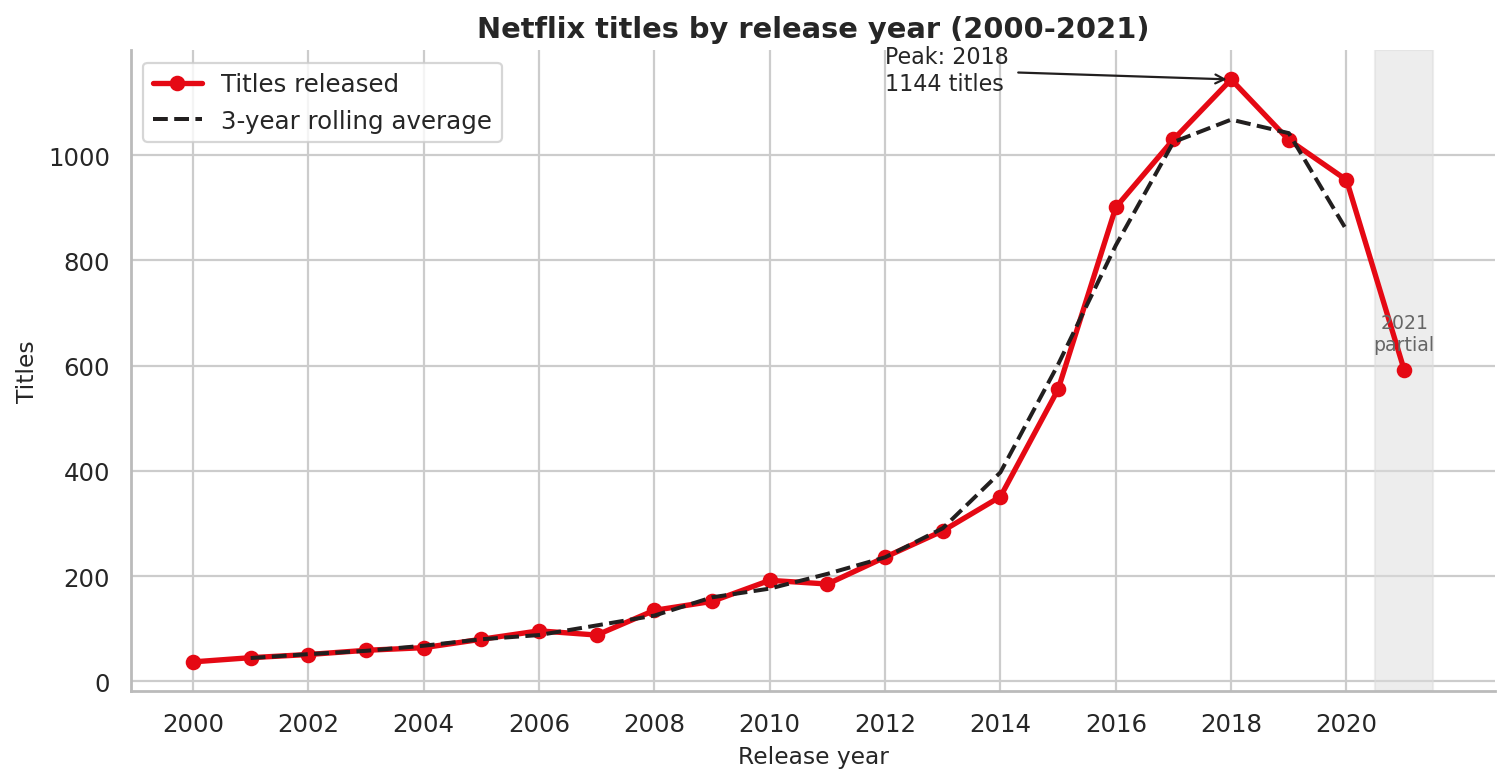

WindowsPath('C:/Users/welcome/Downloads/Task_4_Trend_Analysis_By_Release_Year/Task_4_Trend_Analysis_By_Release_Year/outputs/charts/task4_01_release_trend.png')

In [7]:
# 4.1 Main trend line (all titles) with 3-year rolling average
fig, ax = plt.subplots(figsize=(11, 5.2))
ax.plot(yearly.index, yearly.titles, color=RED, marker="o", lw=2.4, label="Titles released")
ax.plot(yearly.index, yearly.rolling_3yr_avg, color=DARK, ls="--", lw=1.8, label="3-year rolling average")
ax.annotate(f"Peak: {peak_year}\n{peak_val} titles", xy=(peak_year, peak_val), xytext=(peak_year - 6, peak_val - 20),
            arrowprops=dict(arrowstyle="->", color=DARK), fontsize=10)
ax.axvspan(2020.5, 2021.5, color="#ddd", alpha=.5); ax.text(2021, yearly.titles.max() * .55, "2021\npartial", ha="center", fontsize=8.5, color="#666")
ax.set_title("Netflix titles by release year (2000-2021)"); ax.set_xlabel("Release year"); ax.set_ylabel("Titles"); ax.legend(loc="upper left")
ax.set_xticks(range(2000, 2022, 2))
save_fig(fig, "task4_01_release_trend")

  saved -> outputs\charts\task4_02_type_trend.png


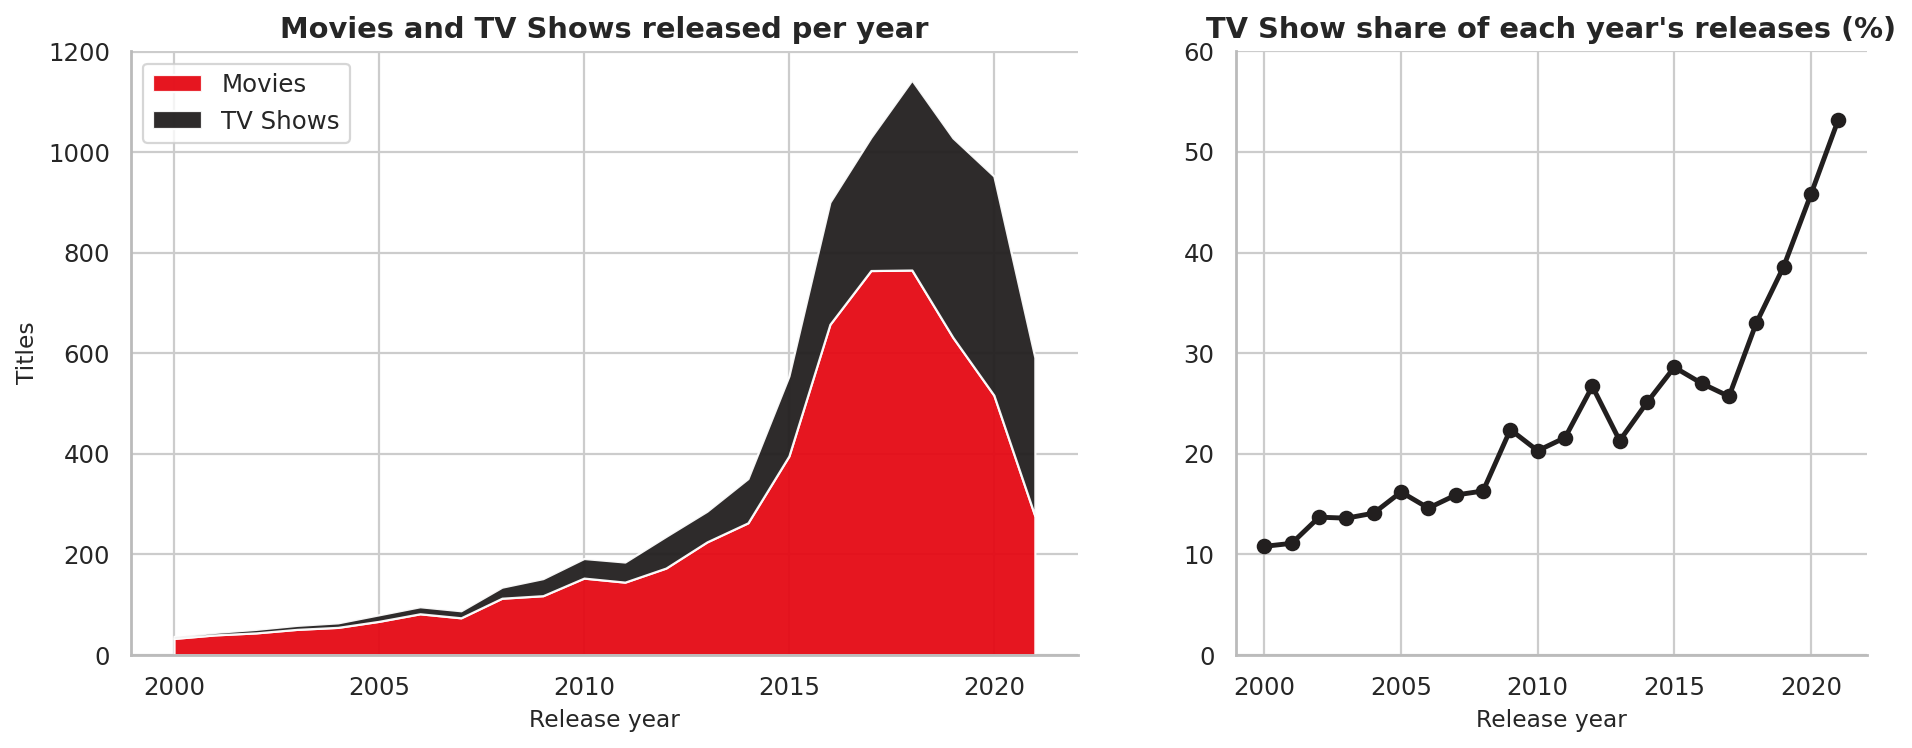

WindowsPath('C:/Users/welcome/Downloads/Task_4_Trend_Analysis_By_Release_Year/Task_4_Trend_Analysis_By_Release_Year/outputs/charts/task4_02_type_trend.png')

In [8]:
# 4.2 Movies vs TV shows (stacked area) + TV share
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9), gridspec_kw=dict(width_ratios=[1.5, 1]))
axes[0].stackplot(yearly.index, yearly.movies, yearly.tv_shows, colors=[RED, DARK], labels=["Movies", "TV Shows"], alpha=.95)
axes[0].set_title("Movies and TV Shows released per year"); axes[0].set_xlabel("Release year"); axes[0].set_ylabel("Titles"); axes[0].legend(loc="upper left")
axes[1].plot(yearly.index, yearly.tv_share_pct, color=DARK, marker="o", lw=2.2)
axes[1].set_title("TV Show share of each year's releases (%)"); axes[1].set_xlabel("Release year"); axes[1].set_ylim(0, 60)
save_fig(fig, "task4_02_type_trend")

  saved -> outputs\charts\task4_03_yoy_growth.png


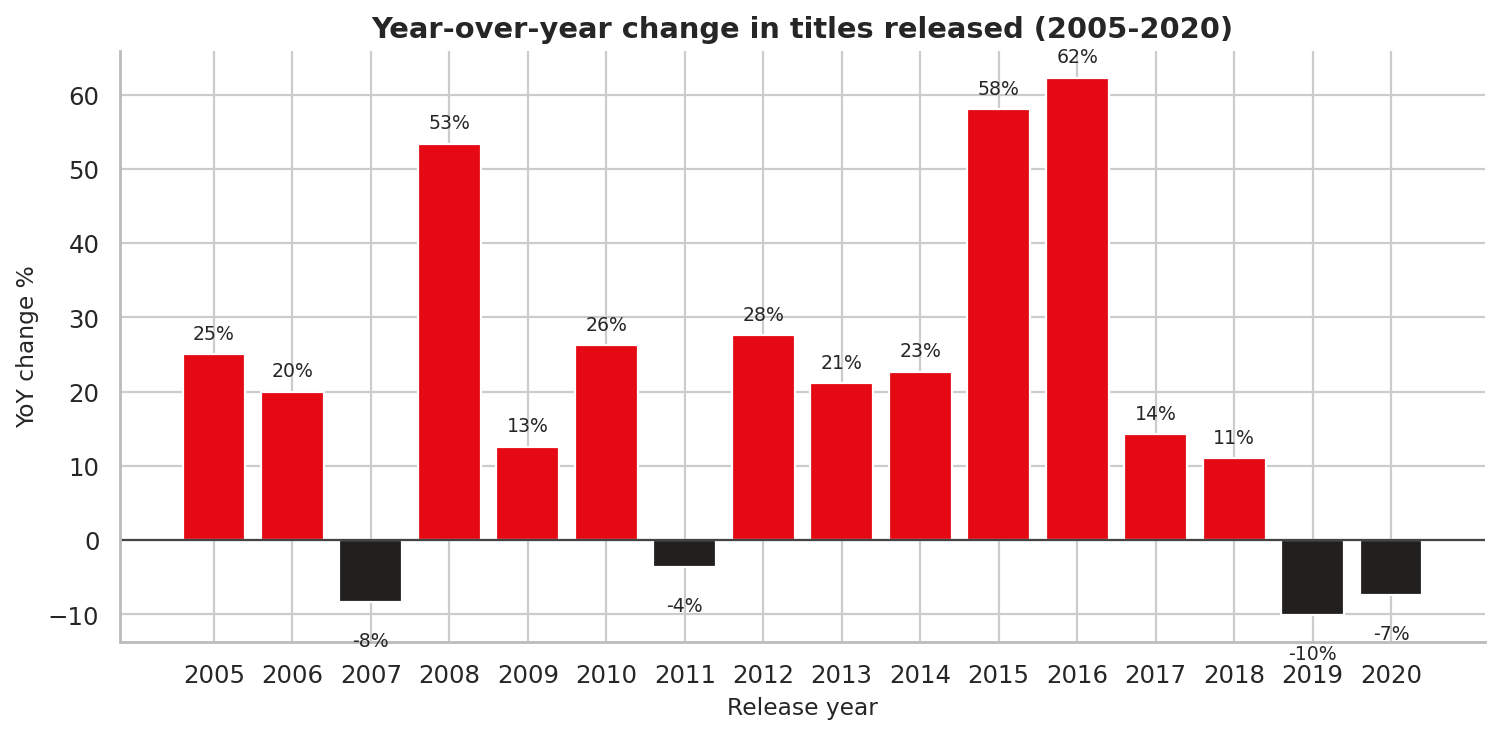

WindowsPath('C:/Users/welcome/Downloads/Task_4_Trend_Analysis_By_Release_Year/Task_4_Trend_Analysis_By_Release_Year/outputs/charts/task4_03_yoy_growth.png')

In [9]:
# 4.3 Year-over-year growth
fig, ax = plt.subplots(figsize=(11, 4.8))
yy2 = yearly.loc[2005:2020]
ax.bar(yy2.index, yy2.yoy_pct, color=[RED if v >= 0 else DARK for v in yy2.yoy_pct])
for x, v in zip(yy2.index, yy2.yoy_pct):
    ax.text(x, v + (2 if v >= 0 else -6), f"{v:.0f}%", ha="center", fontsize=8.5)
ax.axhline(0, color="#444", lw=1); ax.set_title("Year-over-year change in titles released (2005-2020)")
ax.set_xlabel("Release year"); ax.set_ylabel("YoY change %"); ax.set_xticks(yy2.index)
save_fig(fig, "task4_03_yoy_growth")

  saved -> outputs\charts\task4_04_released_vs_added.png


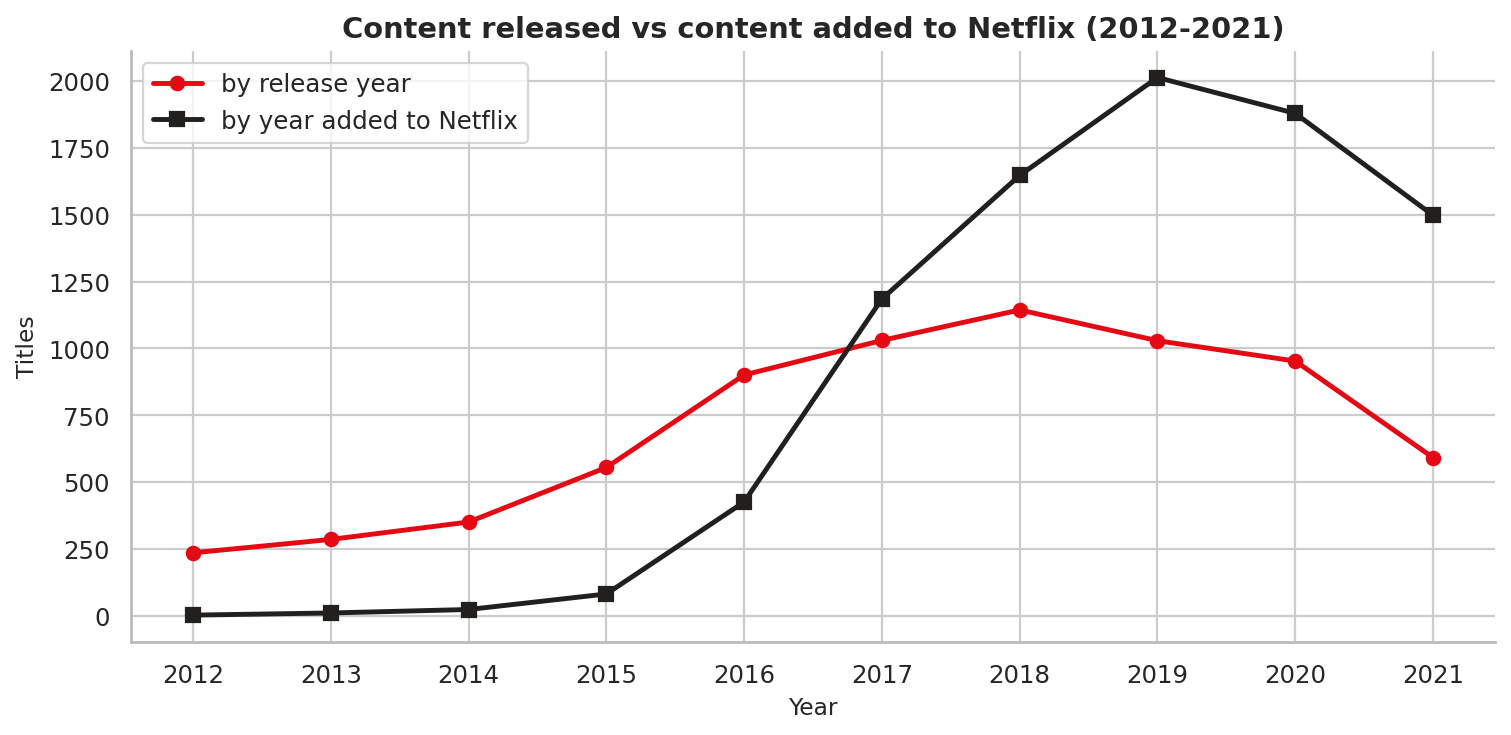

WindowsPath('C:/Users/welcome/Downloads/Task_4_Trend_Analysis_By_Release_Year/Task_4_Trend_Analysis_By_Release_Year/outputs/charts/task4_04_released_vs_added.png')

In [10]:
# 4.4 Release year vs year the title was added to Netflix  (the "catalogue freshness" story)
added = df[df.year_added >= 2012].groupby("year_added").size()
rel = df[df.release_year >= 2012].groupby("release_year").size()
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.plot(rel.index, rel.values, color=RED, marker="o", lw=2.2, label="by release year")
ax.plot(added.index, added.values, color=DARK, marker="s", lw=2.2, label="by year added to Netflix")
ax.set_title("Content released vs content added to Netflix (2012-2021)"); ax.set_xlabel("Year"); ax.set_ylabel("Titles"); ax.legend()
ax.set_xticks(range(2012, 2022))
save_fig(fig, "task4_04_released_vs_added")

  saved -> outputs\charts\task4_05_content_freshness.png


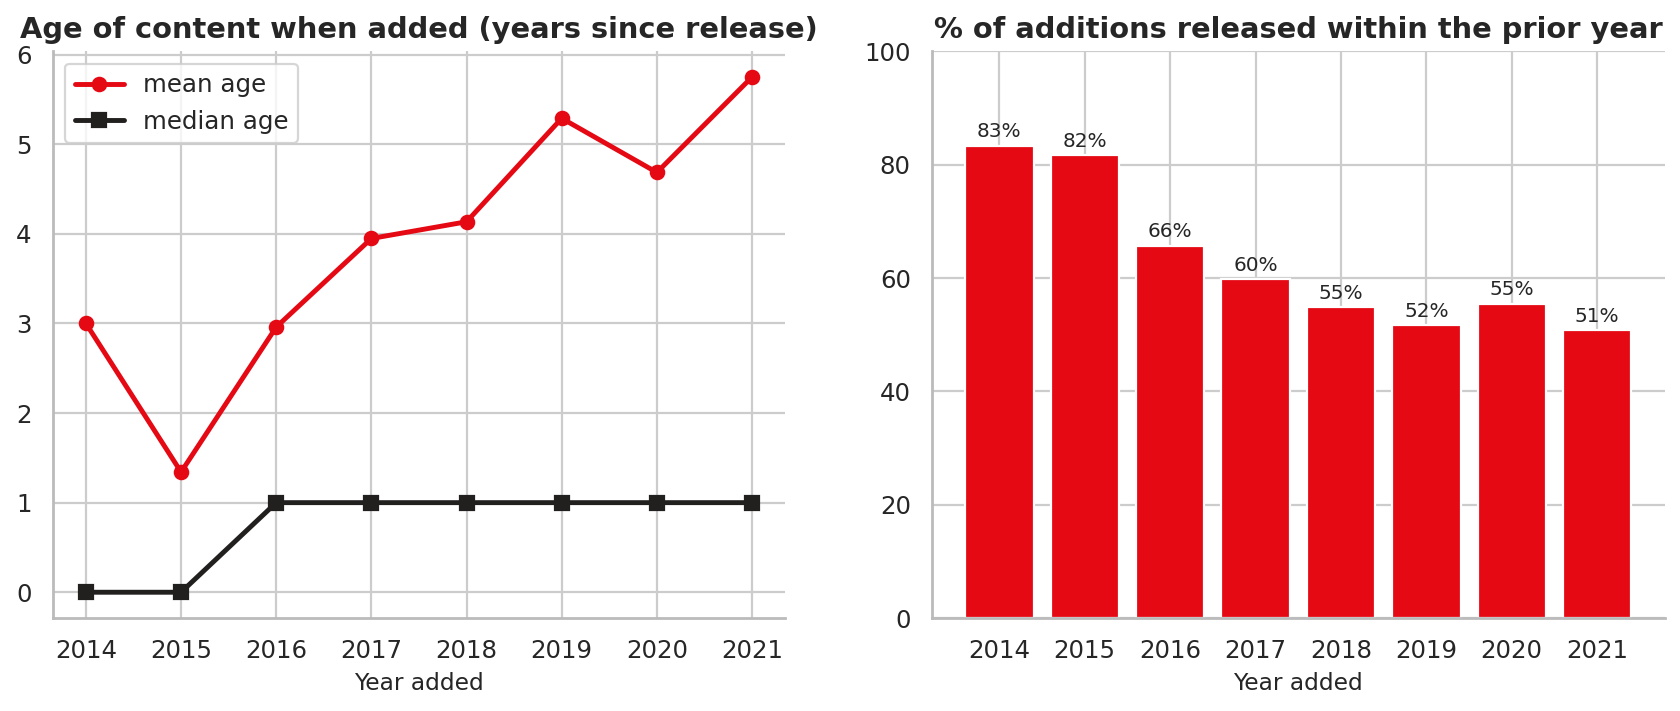

WindowsPath('C:/Users/welcome/Downloads/Task_4_Trend_Analysis_By_Release_Year/Task_4_Trend_Analysis_By_Release_Year/outputs/charts/task4_05_content_freshness.png')

In [11]:
# 4.5 How old is the content when Netflix adds it?  (year_added - release_year)
df["lag_years"] = df.year_added - df.release_year
lag = df[(df.year_added >= 2014) & (df.lag_years >= 0)].groupby("year_added").lag_years.agg(["median", "mean"])
same_year = (df[df.year_added >= 2014].assign(new=lambda d: d.lag_years <= 1).groupby("year_added").new.mean() * 100)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
axes[0].plot(lag.index, lag["mean"], color=RED, marker="o", lw=2.2, label="mean age"); axes[0].plot(lag.index, lag["median"], color=DARK, marker="s", lw=2.2, label="median age")
axes[0].set_title("Age of content when added (years since release)"); axes[0].set_xlabel("Year added"); axes[0].legend()
axes[1].bar(same_year.index, same_year.values, color=RED); axes[1].set_title("% of additions released within the prior year")
axes[1].set_xlabel("Year added"); axes[1].set_ylim(0, 100)
for x, v in zip(same_year.index, same_year.values): axes[1].text(x, v + 1.5, f"{v:.0f}%", ha="center", fontsize=9)
save_fig(fig, "task4_05_content_freshness")

  saved -> outputs\charts\task4_06_monthly_seasonality.png


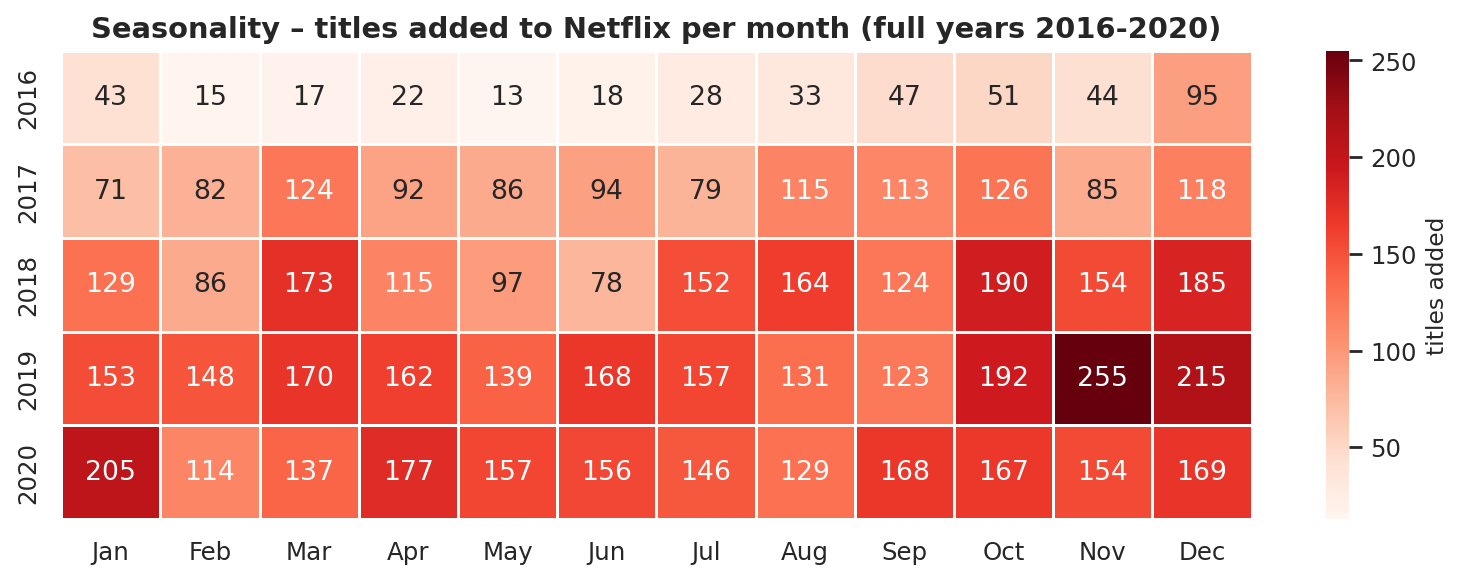

WindowsPath('C:/Users/welcome/Downloads/Task_4_Trend_Analysis_By_Release_Year/Task_4_Trend_Analysis_By_Release_Year/outputs/charts/task4_06_monthly_seasonality.png')

In [12]:
# 4.6 Heatmap: genre-free view -> month x year additions (seasonality)
season = df[df.year_added.between(2016, 2020)].pivot_table(index="year_added", columns="month_added", values="show_id", aggfunc="count")
season.columns = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(season, annot=True, fmt=".0f", cmap="Reds", linewidths=.5, cbar_kws=dict(label="titles added"), ax=ax)
ax.set_title("Seasonality – titles added to Netflix per month (full years 2016-2020)"); ax.set_ylabel(""); ax.set_xlabel("")
save_fig(fig, "task4_06_monthly_seasonality")

### Dashboard screenshot

  saved -> outputs\screenshots\task4_dashboard.png


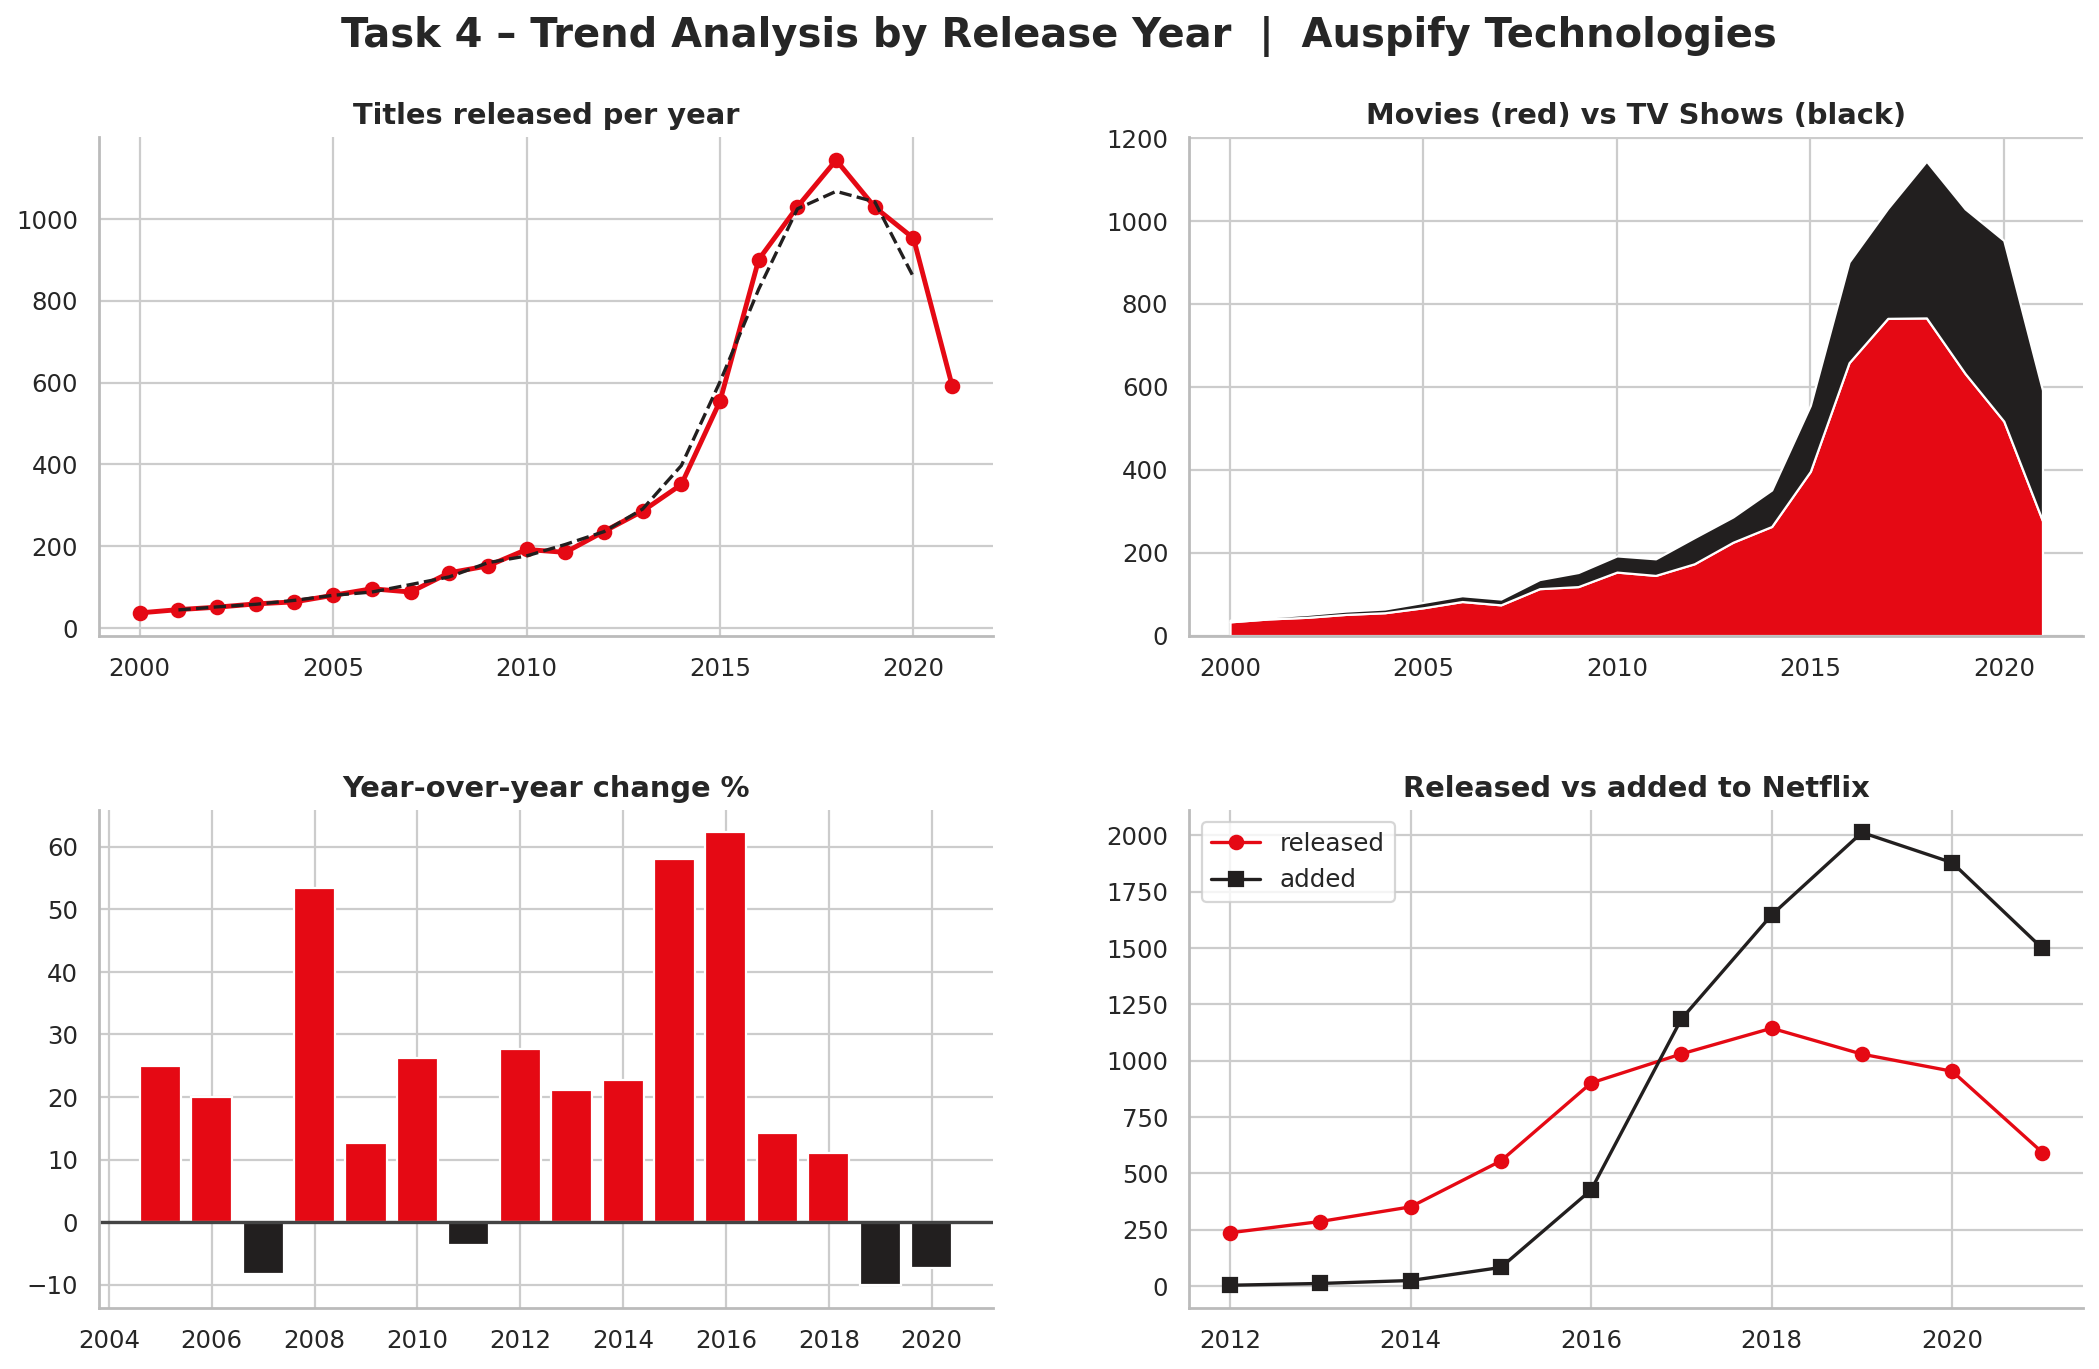

WindowsPath('C:/Users/welcome/Downloads/Task_4_Trend_Analysis_By_Release_Year/Task_4_Trend_Analysis_By_Release_Year/outputs/screenshots/task4_dashboard.png')

In [13]:
fig = plt.figure(figsize=(16, 9.5))
gs = fig.add_gridspec(2, 2, hspace=0.35, wspace=0.22)
ax = fig.add_subplot(gs[0, 0]); ax.plot(yearly.index, yearly.titles, color=RED, marker="o", lw=2.2)
ax.plot(yearly.index, yearly.rolling_3yr_avg, color=DARK, ls="--"); ax.set_title("Titles released per year")
ax = fig.add_subplot(gs[0, 1]); ax.stackplot(yearly.index, yearly.movies, yearly.tv_shows, colors=[RED, DARK]); ax.set_title("Movies (red) vs TV Shows (black)")
ax = fig.add_subplot(gs[1, 0]); ax.bar(yy2.index, yy2.yoy_pct, color=[RED if v >= 0 else DARK for v in yy2.yoy_pct]); ax.axhline(0, color="#444"); ax.set_title("Year-over-year change %")
ax = fig.add_subplot(gs[1, 1]); ax.plot(rel.index, rel.values, color=RED, marker="o", label="released"); ax.plot(added.index, added.values, color=DARK, marker="s", label="added"); ax.legend(); ax.set_title("Released vs added to Netflix")
fig.suptitle("Task 4 – Trend Analysis by Release Year  |  Auspify Technologies", fontsize=18, fontweight="bold", y=0.96)
save_fig(fig, "task4_dashboard", SHOTS)

## Step 5 – Interpret business patterns

In [14]:
share_2015_2018 = pct(yearly.loc[2015:2018, "titles"].sum(), len(df))
decline_2018_2020_movies = (yearly.loc[2020, "movies"] / yearly.loc[2018, "movies"] - 1) * 100
decline_2018_2020_tv = (yearly.loc[2020, "tv_shows"] / yearly.loc[2018, "tv_shows"] - 1) * 100
tv_share_2010 = yearly.loc[2010, "tv_share_pct"]; tv_share_2020 = yearly.loc[2020, "tv_share_pct"]
lag_med_2014 = float(lag.loc[2014, "median"]); lag_med_2020 = float(lag.loc[2020, "median"])
new_2016, new_2020 = float(same_year.loc[2016]), float(same_year.loc[2020])
peak_month = season.sum().idxmax(); low_month = season.sum().idxmin()
pre2000 = int((df.release_year < 2000).sum())

metrics = dict(peak_year=peak_year, peak_titles=peak_val, cagr_2010_2018=round(cagr_2010_2018, 1),
               change_2018_2020=round(decline_2018_2020, 1), movies_change_2018_2020=round(decline_2018_2020_movies, 1),
               tv_change_2018_2020=round(decline_2018_2020_tv, 1), share_2015_2018=share_2015_2018, pre2000=pre2000,
               tv_share_2010=float(tv_share_2010), tv_share_2020=float(tv_share_2020), lag_median_2014=lag_med_2014,
               lag_median_2020=lag_med_2020, new_content_pct_2016=round(new_2016, 1), new_content_pct_2020=round(new_2020, 1),
               peak_month=peak_month, low_month=low_month,
               yearly_titles={int(k): int(v) for k, v in yearly.titles.items()},
               yearly_movies={int(k): int(v) for k, v in yearly.movies.items()},
               yearly_tv={int(k): int(v) for k, v in yearly.tv_shows.items()},
               added_per_year={int(k): int(v) for k, v in added.items()})
save_metrics("task4", metrics)

ph = "\n".join(f"| {r.period} | {r.total:,} | {r.avg_per_year} |" for r in phase.itertuples())
insights = f"""# Task 4 – Trend Analysis by Release Year: Business Patterns

| Period | Titles released | Avg / year |
|---|---|---|
{ph}

## Trends identified
1. **Rapid growth 2010-2018** – annual releases grew at a **{cagr_2010_2018:.1f}% CAGR** from {int(yearly.loc[2010,'titles'])} (2010) to {int(yearly.loc[2018,'titles'])} (2018);
   the peak year was **{peak_year}** with {peak_val} titles. The four years 2015-2018 hold **{share_2015_2018}%** of the whole catalogue.
2. **Decline after the peak is a movie story** – total releases fell **{abs(decline_2018_2020):.0f}%** between 2018 and 2020,
   but that is driven by movies ({decline_2018_2020_movies:+.1f}%) while TV shows actually grew ({decline_2018_2020_tv:+.1f}%).
   2021 is a partial year (data ends September 2021) and should not be read as a collapse. The 2020 dip coincides with COVID-19
   production disruption, but the dataset cannot prove that cause.
3. **Thin back-catalogue** – only {pre2000:,} titles ({pct(pre2000, len(df))}%) were released before 2000: the library is overwhelmingly modern.
4. **Mix shift** – TV shows were {tv_share_2010:.0f}% of 2010 releases vs {tv_share_2020:.0f}% in 2020; series are a growing part of production.
5. **Freshness** – the median age of a title when added to Netflix moved from {lag_med_2014:.0f} year(s) in 2014 to {lag_med_2020:.0f} in 2020;
   {new_2016:.0f}% of 2016 additions were released within the prior year vs {new_2020:.0f}% in 2020.
6. **Seasonality** – additions are highest in {peak_month} and lowest in {low_month} (2016-2020 totals), useful for scheduling launches.

## Business interpretation
* Netflix's catalogue was built mainly through a 2015-2019 content-expansion cycle; maintaining that volume requires continued high investment.
* Total releases are below the 2018 peak while TV output is still growing, so the catalogue mix is moving toward series rather than films.
* Back-catalogue titles are a small part of the library (6%); the catalogue in this dataset is dominated by recent content.

*Data: `outputs/reports/task4_yearly_releases.csv`*
"""
write_report("task4_summary.md", insights)
print(insights)

  report -> outputs\reports\task4_summary.md
# Task 4 – Trend Analysis by Release Year: Business Patterns

| Period | Titles released | Avg / year |
|---|---|---|
| 2000-2009 | 807 | 80.7 |
| 2010-2014 | 1,250 | 250.0 |
| 2015-2018 | 3,630 | 907.5 |
| 2019-2021 (2021 partial) | 2,574 | 858.0 |

## Trends identified
1. **Rapid growth 2010-2018** – annual releases grew at a **25.0% CAGR** from 192 (2010) to 1144 (2018);
   the peak year was **2018** with 1144 titles. The four years 2015-2018 hold **41.3%** of the whole catalogue.
2. **Decline after the peak is a movie story** – total releases fell **17%** between 2018 and 2020,
   but that is driven by movies (-32.5%) while TV shows actually grew (+15.3%).
   2021 is a partial year (data ends September 2021) and should not be read as a collapse. The 2020 dip coincides with COVID-19
   production disruption, but the dataset cannot prove that cause.
3. **Thin back-catalogue** – only 525 titles (6.0%) were released before 2000: the library 